In [1]:
import numpy as np
import matplotlib.pyplot as plt

dx = 2.000e-05 m
r = 0.4750


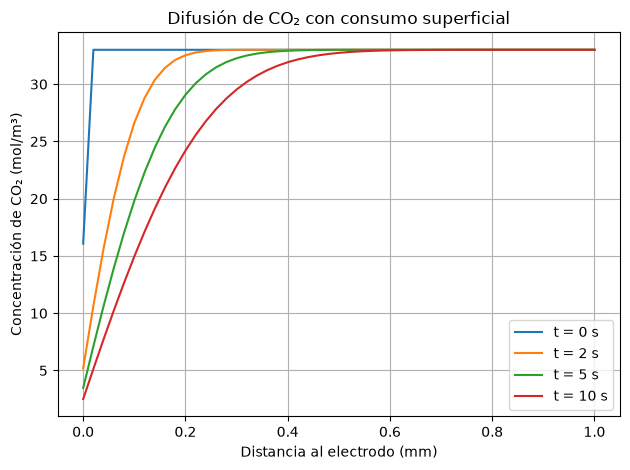

In [3]:


# 1. Parámetros físicos
L = 1e-3        # Longitud del líquido (m)
D = 1.9e-9      # Coeficiente de difusión (m²/s)
k = 1e-4        # Constante de consumo superficial (m/s)
C_bulk = 33.0   # Concentración exterior (mol/m³)

# 2. Parámetros numéricos
N = 50          # Número de intervalos espaciales
dx = L / N

dt = 0.1        # Paso temporal (s)
t_final = 10    # Tiempo total (s)
n_steps = int(t_final / dt)

# 3. Comprobar estabilidad
r = D * dt / dx**2

print(f"dx = {dx:.3e} m")
print(f"r = {r:.4f}")

if r > 0.5:
    raise ValueError("El paso temporal es demasiado grande para este esquema.")

# 4. Construir las mallas
x = np.linspace(0, L, N + 1)
t = np.arange(n_steps + 1) * dt

# 5. Concentración inicial uniforme
C = np.full(N + 1, C_bulk)

# Factor de la condición de frontera del electrodo
alpha = D / (D + k * dx)

# Aplicar las condiciones de frontera iniciales
C[0] = alpha * C[1]
C[-1] = C_bulk

# Guardar la evolución temporal
C_history = np.zeros((n_steps + 1, N + 1))
C_history[0] = C.copy()

# 6. Resolver la ecuación de difusión
for n in range(n_steps):

    C_new = C.copy()

    # Actualizar solo los puntos interiores
    C_new[1:N] = C[1:N] + r * (
        C[2:N+1] - 2*C[1:N] + C[0:N-1]
    )

    # Frontera del electrodo: x = 0
    C_new[0] = alpha * C_new[1]

    # Frontera exterior: x = L
    C_new[-1] = C_bulk

    # Avanzar al siguiente instante
    C = C_new
    C_history[n + 1] = C.copy()

# 7. Graficar perfiles de concentración
for tiempo in [0, 2, 5, 10]:
    indice = int(tiempo / dt)
    plt.plot(
        x * 1e3,
        C_history[indice],
        label=f"t = {tiempo} s"
    )

plt.xlabel("Distancia al electrodo (mm)")
plt.ylabel("Concentración de CO₂ (mol/m³)")
plt.title("Difusión de CO₂ con consumo superficial")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
